<a href="https://colab.research.google.com/github/rgrion/dssagricola/blob/main/dss_agricola.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# BLOCO 1 - Carregamento e conferência do dataset
# Projeto DSS Cana-de-Açúcar

import pandas as pd
from google.colab import files

print("Selecione o arquivo FAOSTAT_sugarcane.csv")
arquivos = files.upload()

nome_arquivo = next(iter(arquivos))
df = pd.read_csv(nome_arquivo)

print("\n=== INFORMAÇÕES GERAIS ===")
print(f"Quantidade de registros: {len(df)}")
print(f"Quantidade de colunas: {len(df.columns)}")
print(f"Período: {df['Year'].min()} a {df['Year'].max()}")

print("\n=== INDICADORES DISPONÍVEIS ===")
print(df["Element"].unique())

print("\n=== UNIDADES DOS INDICADORES ===")
print(df.groupby("Element")["Unit"].unique())

print("\n=== VALORES AUSENTES NAS COLUNAS PRINCIPAIS ===")
print(df[["Year", "Element", "Value"]].isnull().sum())

print("\n=== PRIMEIROS REGISTROS ===")
print(df[["Year", "Item", "Element", "Value", "Unit"]].head(9).to_string(index=False))


Selecione o arquivo FAOSTAT_sugarcane.csv


Saving FAOSTAT_sugarcane.csv to FAOSTAT_sugarcane (1).csv

=== INFORMAÇÕES GERAIS ===
Quantidade de registros: 30
Quantidade de colunas: 15
Período: 2015 a 2024

=== INDICADORES DISPONÍVEIS ===
['Area harvested' 'Yield' 'Production']

=== UNIDADES DOS INDICADORES ===
Element
Area harvested       [ha]
Production            [t]
Yield             [kg/ha]
Name: Unit, dtype: object

=== VALORES AUSENTES NAS COLUNAS PRINCIPAIS ===
Year       0
Element    0
Value      0
dtype: int64

=== PRIMEIROS REGISTROS ===
 Year       Item        Element       Value  Unit
 2015 Sugar cane Area harvested  10111376.0    ha
 2015 Sugar cane          Yield     74202.6 kg/ha
 2015 Sugar cane     Production 750290277.0     t
 2016 Sugar cane Area harvested  10223894.0    ha
 2016 Sugar cane          Yield     75176.3 kg/ha
 2016 Sugar cane     Production 768594154.0     t
 2017 Sugar cane Area harvested  10189208.0    ha
 2017 Sugar cane          Yield     74455.9 kg/ha
 2017 Sugar cane     Production 75864620

In [2]:

# BLOCO 2 - Organização e análise exploratória

# Organizar os indicadores em colunas
dados = df.pivot(
    index="Year",
    columns="Element",
    values="Value"
).reset_index()

# Renomear colunas
dados = dados.rename(columns={
    "Year": "Ano",
    "Production": "Producao_t",
    "Area harvested": "Area_ha",
    "Yield": "Produtividade_kg_ha"
})

# Organizar os anos em ordem crescente
dados = dados.sort_values("Ano").reset_index(drop=True)

# Criar indicadores em unidades mais fáceis de interpretar
dados["Producao_milhoes_t"] = dados["Producao_t"] / 1_000_000
dados["Area_milhoes_ha"] = dados["Area_ha"] / 1_000_000

print("=== DADOS ORGANIZADOS ===")
print(
    dados[[
        "Ano",
        "Producao_milhoes_t",
        "Area_milhoes_ha",
        "Produtividade_kg_ha"
    ]].round(2).to_string(index=False)
)

print("\n=== ESTATÍSTICAS DA PRODUÇÃO ===")
print(f"Produção média: {dados['Producao_milhoes_t'].mean():.2f} milhões t")
print(f"Menor produção: {dados['Producao_milhoes_t'].min():.2f} milhões t")
print(f"Maior produção: {dados['Producao_milhoes_t'].max():.2f} milhões t")

ano_min = dados.loc[dados["Producao_t"].idxmin(), "Ano"]
ano_max = dados.loc[dados["Producao_t"].idxmax(), "Ano"]

print(f"Ano de menor produção: {ano_min}")
print(f"Ano de maior produção: {ano_max}")

# Variação percentual entre anos consecutivos
dados["Variacao_percentual"] = (
    dados["Producao_t"].pct_change() * 100
)

print("\n=== VARIAÇÃO ANUAL DA PRODUÇÃO (%) ===")
print(
    dados[["Ano", "Variacao_percentual"]]
    .round(2)
    .to_string(index=False, na_rep="—")
)


=== DADOS ORGANIZADOS ===
 Ano  Producao_milhoes_t  Area_milhoes_ha  Produtividade_kg_ha
2015              750.29            10.11              74202.6
2016              768.59            10.22              75176.3
2017              758.65            10.19              74455.9
2018              747.56            10.02              74575.9
2019              753.47            10.09              74657.0
2020              756.07            10.00              75636.3
2021              715.68             9.97              71773.4
2022              725.73             9.88              73434.9
2023              782.06            10.04              77900.9
2024              759.66            10.05              75578.7

=== ESTATÍSTICAS DA PRODUÇÃO ===
Produção média: 751.78 milhões t
Menor produção: 715.68 milhões t
Maior produção: 782.06 milhões t
Ano de menor produção: 2021
Ano de maior produção: 2023

=== VARIAÇÃO ANUAL DA PRODUÇÃO (%) ===
 Ano  Variacao_percentual
2015                    —


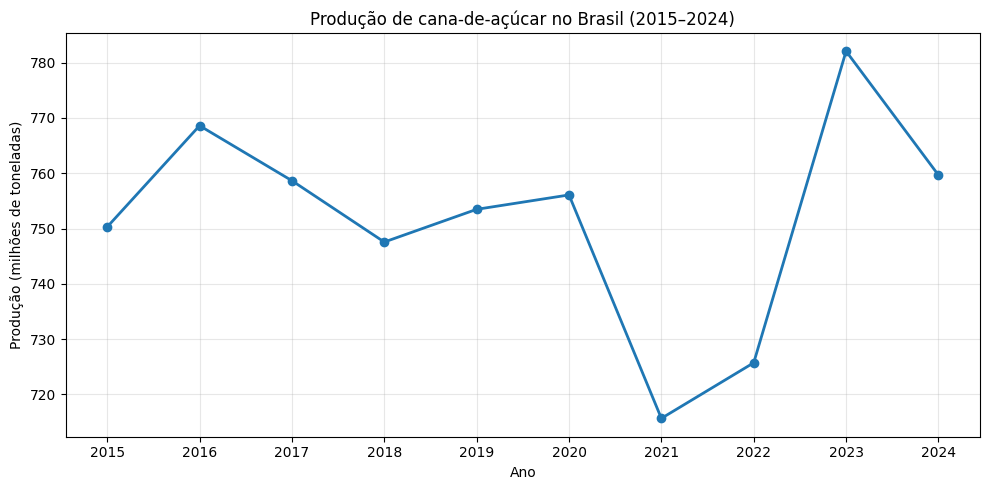

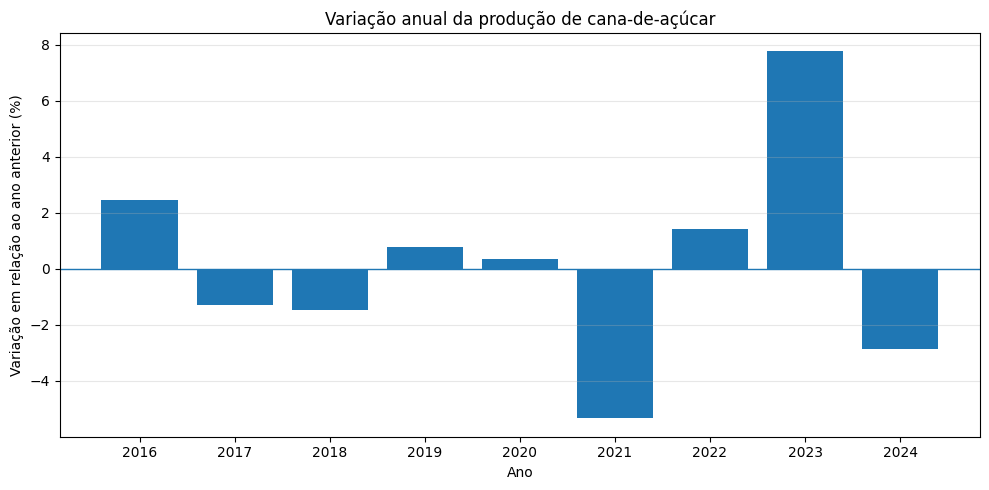

=== GRÁFICOS GERADOS ===
1. grafico_producao_cana.png
2. grafico_variacao_cana.png
Fonte: FAOSTAT (2015–2024).


In [3]:

# BLOCO 3 - Visualização da produção de cana-de-açúcar

import matplotlib.pyplot as plt
from google.colab import files

# GRÁFICO 1 - Evolução da produção
plt.figure(figsize=(10, 5))

plt.plot(
    dados["Ano"],
    dados["Producao_milhoes_t"],
    marker="o",
    linewidth=2
)

plt.title("Produção de cana-de-açúcar no Brasil (2015–2024)")
plt.xlabel("Ano")
plt.ylabel("Produção (milhões de toneladas)")
plt.xticks(dados["Ano"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("grafico_producao_cana.png", dpi=300)
plt.show()

# GRÁFICO 2 - Variação anual da produção
plt.figure(figsize=(10, 5))

plt.bar(
    dados["Ano"].iloc[1:],
    dados["Variacao_percentual"].iloc[1:]
)

plt.axhline(0, linewidth=1)
plt.title("Variação anual da produção de cana-de-açúcar")
plt.xlabel("Ano")
plt.ylabel("Variação em relação ao ano anterior (%)")
plt.xticks(dados["Ano"].iloc[1:])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("grafico_variacao_cana.png", dpi=300)
plt.show()

print("=== GRÁFICOS GERADOS ===")
print("1. grafico_producao_cana.png")
print("2. grafico_variacao_cana.png")
print("Fonte: FAOSTAT (2015–2024).")


In [4]:

# BLOCO 4 - Preparação dos dados para modelagem

# Criar variável com a produção do ano anterior
dados["Producao_ano_anterior"] = (
    dados["Producao_milhoes_t"].shift(1)
)

# Remover a primeira linha, que não possui ano anterior
modelo_dados = dados.dropna(
    subset=["Producao_ano_anterior"]
).copy()

# Separação cronológica:
# Treinamento: 2016 a 2022
# Teste: 2023 e 2024
treino = modelo_dados[
    modelo_dados["Ano"] <= 2022
].copy()

teste = modelo_dados[
    modelo_dados["Ano"] >= 2023
].copy()

# Variável de entrada e variável a prever
X_treino = treino[["Producao_ano_anterior"]]
y_treino = treino["Producao_milhoes_t"]

X_teste = teste[["Producao_ano_anterior"]]
y_teste = teste["Producao_milhoes_t"]

print("=== DADOS PREPARADOS ===")
print(
    modelo_dados[[
        "Ano",
        "Producao_ano_anterior",
        "Producao_milhoes_t"
    ]].round(2).to_string(index=False)
)

print("\n=== DIVISÃO DOS DADOS ===")
print("Anos de treinamento:", treino["Ano"].tolist())
print("Anos de teste:", teste["Ano"].tolist())

print("\nQuantidade de exemplos de treinamento:", len(treino))
print("Quantidade de exemplos de teste:", len(teste))

print("\n=== DADOS DE TESTE ===")
print(
    teste[[
        "Ano",
        "Producao_ano_anterior",
        "Producao_milhoes_t"
    ]].round(2).to_string(index=False)
)


=== DADOS PREPARADOS ===
 Ano  Producao_ano_anterior  Producao_milhoes_t
2016                 750.29              768.59
2017                 768.59              758.65
2018                 758.65              747.56
2019                 747.56              753.47
2020                 753.47              756.07
2021                 756.07              715.68
2022                 715.68              725.73
2023                 725.73              782.06
2024                 782.06              759.66

=== DIVISÃO DOS DADOS ===
Anos de treinamento: [2016, 2017, 2018, 2019, 2020, 2021, 2022]
Anos de teste: [2023, 2024]

Quantidade de exemplos de treinamento: 7
Quantidade de exemplos de teste: 2

=== DADOS DE TESTE ===
 Ano  Producao_ano_anterior  Producao_milhoes_t
2023                 725.73              782.06
2024                 782.06              759.66


In [5]:

# BLOCO 5 - Modelagem preditiva inicial
# Comparação: Persistência x Regressão Linear

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Modelo de referência: produção igual à do ano anterior
previsao_referencia = X_teste["Producao_ano_anterior"].to_numpy()

# 2. Treinar o modelo de Regressão Linear
modelo_linear = LinearRegression()
modelo_linear.fit(X_treino, y_treino)

# Realizar previsões para 2023 e 2024
previsao_linear = modelo_linear.predict(X_teste)

# 3. Função para calcular métricas de avaliação
def avaliar_modelo(real, previsto):
    mae = mean_absolute_error(real, previsto)
    rmse = np.sqrt(mean_squared_error(real, previsto))
    mape = np.mean(
        np.abs((np.array(real) - np.array(previsto))
               / np.array(real))
    ) * 100

    return mae, rmse, mape

# Avaliar os dois modelos
mae_ref, rmse_ref, mape_ref = avaliar_modelo(
    y_teste, previsao_referencia
)

mae_lin, rmse_lin, mape_lin = avaliar_modelo(
    y_teste, previsao_linear
)

# 4. Apresentar previsões
resultados = pd.DataFrame({
    "Ano": teste["Ano"].values,
    "Producao_real": y_teste.values,
    "Previsao_referencia": previsao_referencia,
    "Previsao_linear": previsao_linear
})

print("=== PREVISÕES (MILHÕES DE TONELADAS) ===")
print(resultados.round(2).to_string(index=False))

# 5. Comparar métricas
metricas = pd.DataFrame({
    "Modelo": ["Persistência", "Regressão Linear"],
    "MAE": [mae_ref, mae_lin],
    "RMSE": [rmse_ref, rmse_lin],
    "MAPE (%)": [mape_ref, mape_lin]
})

print("\n=== AVALIAÇÃO DOS MODELOS ===")
print(metricas.round(2).to_string(index=False))

# 6. Exibir parâmetros da Regressão Linear
print("\n=== PARÂMETROS DA REGRESSÃO LINEAR ===")
print(f"Coeficiente: {modelo_linear.coef_[0]:.4f}")
print(f"Intercepto: {modelo_linear.intercept_:.4f}")

print("\nObservação: avaliação exploratória com apenas 2 anos de teste.")


=== PREVISÕES (MILHÕES DE TONELADAS) ===
 Ano  Producao_real  Previsao_referencia  Previsao_linear
2023         782.06               725.73           735.01
2024         759.66               782.06           761.70

=== AVALIAÇÃO DOS MODELOS ===
          Modelo   MAE  RMSE  MAPE (%)
    Persistência 39.36 42.86      5.08
Regressão Linear 24.54 33.30      3.14

=== PARÂMETROS DA REGRESSÃO LINEAR ===
Coeficiente: 0.4738
Intercepto: 391.1688

Observação: avaliação exploratória com apenas 2 anos de teste.


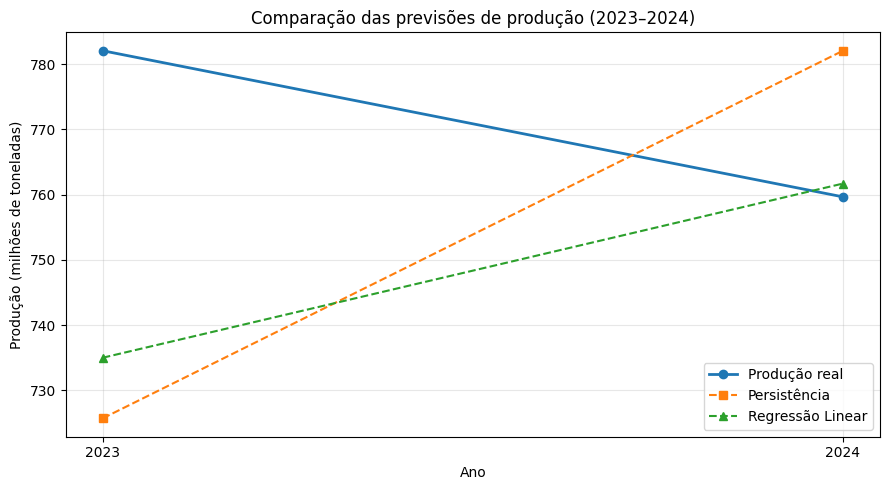

Gráfico salvo: grafico_comparacao_modelos.png
Fonte: FAOSTAT (2015–2024).
Elaboração: autoras do projeto.


In [6]:

# BLOCO 6 - Comparação visual das previsões

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    resultados["Ano"],
    resultados["Producao_real"],
    marker="o",
    linewidth=2,
    label="Produção real"
)

plt.plot(
    resultados["Ano"],
    resultados["Previsao_referencia"],
    marker="s",
    linestyle="--",
    label="Persistência"
)

plt.plot(
    resultados["Ano"],
    resultados["Previsao_linear"],
    marker="^",
    linestyle="--",
    label="Regressão Linear"
)

plt.title("Comparação das previsões de produção (2023–2024)")
plt.xlabel("Ano")
plt.ylabel("Produção (milhões de toneladas)")
plt.xticks(resultados["Ano"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafico_comparacao_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo: grafico_comparacao_modelos.png")
print("Fonte: FAOSTAT (2015–2024).")
print("Elaboração: autoras do projeto.")
